The Ministry of Agriculture wants to define **Agricultural Zones** — regions that share similar soil chemistry, climate, and terrain characteristics regardless of which administrative province they fall within. This is a different question from crop classification: we are not asking *what crop grows here*, we are asking *which fields are fundamentally similar to each other?*

Zones defined this way can drive practical policy: shared irrigation infrastructure, bulk fertilizer procurement, pest management programs, and climate resilience planning — all calibrated to the actual agricultural character of the land rather than historical administrative boundaries.

Your tools this week are:

- **K-Means Clustering:** Find the optimal number of zones using the Elbow Method, then group all 5,654 fields into those zones.
- **Hierarchical Clustering:** Build a dendrogram that shows how zones relate to each other — which zones are more similar, and how they would merge if we needed fewer zones.
- **Cluster Centroid Interpretation:** Translate the mathematical zone descriptions into human-readable Agricultural Zone personas that the ministry can use in planning documents.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram


In [4]:
import os

# Database file
db_file = 'Maji_Ndogo_farm_survey_small.db'

# Check whether the database exists
if not os.path.exists(db_file):
    raise FileNotFoundError(
        f"Database file '{db_file}' not found. "
        "Please place it in the same folder as this notebook."
    )

# Create SQLAlchemy engine
engine = create_engine(f'sqlite:///{db_file}')

In [5]:
sql_query = """
SELECT
    Elevation,
    Rainfall,
    Ave_temps,
    Soil_fertility,
    pH,
    Pollution_level,
    Plot_size,
    Standard_yield
FROM geographic_features
LEFT JOIN weather_features USING (Field_ID)
LEFT JOIN soil_and_crop_features USING (Field_ID)
LEFT JOIN farm_management_features USING (Field_ID)
"""

# Execute query using SQLAlchemy
with engine.connect() as connection:
    df = pd.read_sql_query(
        text(sql_query),
        connection
    )

# Remove missing observations
df.dropna(inplace=True)

In [6]:
print(f'Dataset shape: {df.shape}')

display(df.head())

Dataset shape: (5654, 8)


,Elevation,Rainfall,Ave_temps,Soil_fertility,pH,Pollution_level,Plot_size,Standard_yield
0,786.05580,1125.2,15.00,0.62,6.169393,0.085267,1.3,0.577964
1,674.33410,1450.7,13.35,0.64,5.676648,0.399684,2.2,0.486302
2,826.53390,2208.9,13.30,0.69,5.331993,0.358029,3.4,0.649647
3,574.94617,328.8,13.20,0.54,5.328150,0.286687,2.4,0.532348
4,886.35300,785.2,14.25,0.72,5.721234,0.043190,1.5,0.555076


In [8]:
# Check missing values
print("Missing values:")
display(df.isnull().sum())

# Check data types
print("\nData types:")
display(df.dtypes)

# Descriptive statistics
display(df.describe().T)

Missing values:


Elevation          0
Rainfall           0
Ave_temps          0
Soil_fertility     0
pH                 0
Pollution_level    0
Plot_size          0
Standard_yield     0
dtype: int64


Data types:


Elevation          float64
Rainfall           float64
Ave_temps          float64
Soil_fertility     float64
pH                 float64
Pollution_level    float64
Plot_size          float64
Standard_yield     float64
dtype: object

,count,mean,std,min,25%,50%,75%,max
Elevation,5654.0,625.468485,213.768160,-8.788608e+02,520.125410,661.308975,763.366200,1122.252100
Rainfall,5654.0,1201.943244,499.782824,1.031000e+02,773.175000,1200.600000,1625.425000,2470.900000
Ave_temps,5654.0,13.222550,0.801636,1.025000e+01,12.700000,13.200000,13.750000,17.300000
Soil_fertility,5654.0,0.619308,0.044791,5.100000e-01,0.590000,0.620000,0.650000,0.820000
pH,5654.0,5.607073,0.789215,3.700337e+00,5.030630,5.602896,6.162058,7.499959
Pollution_level,5654.0,0.223192,0.223798,1.013245e-10,0.051337,0.164706,0.305889,0.995413
Plot_size,5654.0,3.923965,3.463855,5.000000e-01,1.500000,2.800000,4.700000,15.000000
Standard_yield,5654.0,0.534405,0.111806,1.707173e-01,0.460386,0.528836,0.599942,0.898037


 #### **Challenge 1: Finding the Elbow (K-Means)**

Before we can cluster, we need to decide how many clusters to use. Asking K-Means for 2 zones when 5 exist naturally will give us meaningless groupings. Asking for 20 when the data has only 4 natural groups will give us zones too small to be useful for policy.

The **Elbow Method** helps us find the sweet spot. We run K-Means for values of k from 1 to 10 and record the **inertia** — the sum of squared distances from each point to its assigned cluster center — at each k. As k increases, inertia always decreases (more clusters means each center is closer to its members). The "elbow" is the point where adding another cluster stops giving meaningful gains: the curve bends sharply and then flattens.

#### **Task**
Create a function `get_k_means_inertia` that returns a list of inertia values for each k in the specified range.

**Function specifications:**
- Takes a DataFrame `df` and an iterable `k_range` as input.
- Scales the data using `StandardScaler`.
- For each k in `k_range`, fits a `KMeans` model with `n_clusters=k`, `random_state=42`, and `n_init=10`.
- Returns a **list** of inertia values, one per k, in the order of `k_range`.

> **Note:** `n_init=10` runs K-Means 10 times with different initializations and returns the best result. This avoids the algorithm getting stuck in a local minimum.


In [9]:
def get_k_means_inertia(df, k_range):

    # Scale the dataset
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)

    # Store inertia values
    inertia_values = []

    # Fit K-Means for each value of k
    for k in k_range:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        kmeans.fit(X_scaled)

        # Append inertia
        inertia_values.append(kmeans.inertia_)

    return inertia_values

In [10]:
# Define the range of clusters
k_range = range(1, 11)

# Calculate inertia
inertia_values = get_k_means_inertia(df, k_range)

# Display results
print("Inertia values (k=1 to 10):")

for k, inertia in zip(k_range, inertia_values):
    print(f"k={k}: {inertia:.2f}")

Inertia values (k=1 to 10):
k=1: 45232.00
k=2: 36307.24
k=3: 31194.68
k=4: 27338.84
k=5: 24644.77
k=6: 22664.10
k=7: 21271.08
k=8: 20338.30
k=9: 19441.30
k=10: 18725.28


In [26]:
import matplotlib.pyplot as plt

def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    title_fontsize=14,
    label_fontsize=11,
    remove_spines=True,
    grid=True,
    legend=True,
    xlim=None,
    ylim=None,
):
    """Apply a consistent style to a matplotlib Axes object."""
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=15)

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4, linewidth=0.3, color="gray")
    if legend:
        ax.legend(fontsize=9)

    if remove_spines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        for spine in ax.spines.values():
            spine.set_linewidth(1.2)

    ax.set_facecolor("whitesmoke")

    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)

    return ax


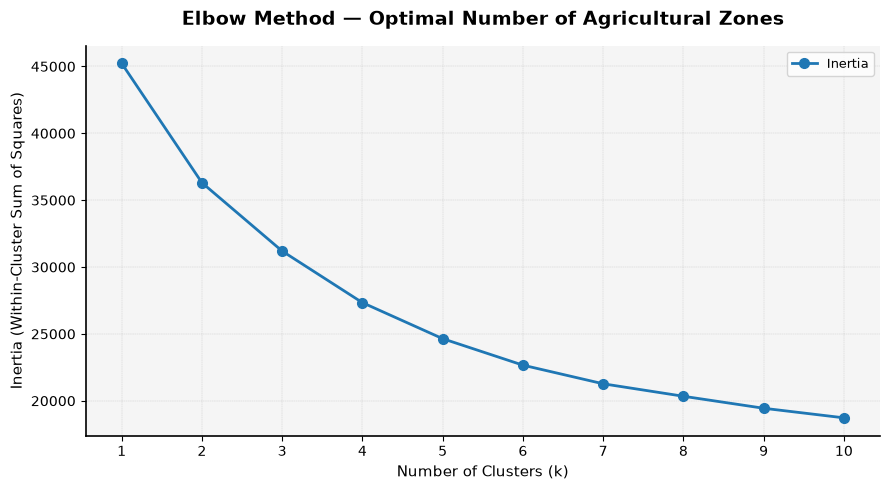

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    list(k_range),
    inertia_values,
    marker='o',
    linewidth=2,
    markersize=7,
    label='Inertia'
)

style_plot(
    ax,
    title='Elbow Method — Optimal Number of Agricultural Zones',
    xlabel='Number of Clusters (k)',
    ylabel='Inertia (Within-Cluster Sum of Squares)',
    legend=True
)

ax.set_xticks(list(k_range))

plt.tight_layout()
plt.show()

__Insight:__

Based on the Elbow Method, 4 or 5 clusters are reasonable candidates for segmenting the agricultural fields into distinct zones. These values offer a balance between cluster compactness and model simplicity.


#### **Challenge 2: The Family Tree (Hierarchical Clustering)**

K-Means assigns each field to exactly one zone. But it cannot tell us how those zones relate to each other. Are zones 1 and 3 more similar than zones 1 and 4? Which zones would merge first if we needed to consolidate from five zones to four?

**Hierarchical clustering** answers these questions. It builds a tree — called a **dendrogram** — by progressively merging the most similar observations. We use **agglomerative clustering** (bottom-up): every field starts in its own cluster, and at each step the two most similar clusters are merged until only one cluster remains.

**Ward's linkage** is the merging rule we use: at each step, merge the two clusters that minimize the increase in total within-cluster variance. This tends to produce compact, well-separated clusters and is the standard choice for most applications.

Because hierarchical clustering computes a distance matrix between all pairs of points, it becomes slow on very large datasets. We work with a **sample of 500 fields** for the dendrogram — enough to reveal the structure without the computational cost.

#### **Task**
Create a function `get_linkage_matrix` that returns a Ward linkage matrix from SciPy.

**Function specifications:**
- Takes a DataFrame `df` as input (this will be a 500-row sample — see the call cell below).
- Scales the data using `StandardScaler`.
- Computes and returns the linkage matrix using `scipy.cluster.hierarchy.linkage` with `method='ward'`.
- The returned array has shape `(n-1, 4)` for an input of n points.


In [13]:
def get_linkage_matrix(df):

    # Scale the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)

    # Compute the Ward linkage matrix
    linkage_matrix = sch.linkage(
        X_scaled,
        method='ward'
    )

    return linkage_matrix

__Select a sample of 500 fields:__

Sampling reduces the computational cost of hierarchical clustering while retaining enough observations to examine the clustering structure.

In [14]:
# Select a random sample of 500 observations
df_sample = df.sample(
    n=500,
    random_state=42
)

# Reset the index
df_sample = df_sample.reset_index(drop=True)

print("Sample shape:", df_sample.shape)

Sample shape: (500, 8)


In [16]:
# Generate the linkage matrix
linkage_matrix = get_linkage_matrix(df_sample)

# Inspect the output
print(f'Linkage matrix shape: {linkage_matrix.shape}')

print("\nLast merge (root of the dendrogram):")
print(linkage_matrix[-1].round(4))

Linkage matrix shape: (499, 4)

Last merge (root of the dendrogram):
[995.     997.      36.3652 500.    ]


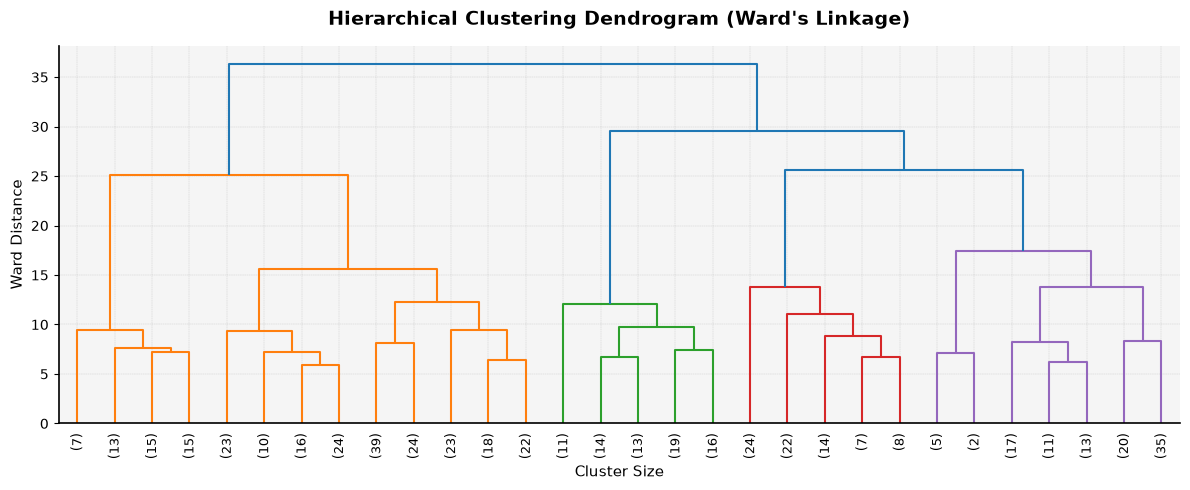

In [17]:
# Visualize the dendrogram
fig, ax = plt.subplots(figsize=(12, 5))

sch.dendrogram(
    linkage_matrix,
    truncate_mode='lastp',  # Show only the last p merged clusters
    p=30,  # Show only the last 30 merged clusters 
    ax=ax, 
    leaf_rotation=90,
    leaf_font_size=9
)

style_plot(
    ax,
    title='Hierarchical Clustering Dendrogram (Ward\'s Linkage)',
    xlabel='Cluster Size',
    ylabel='Ward Distance',
    legend=False
)

plt.tight_layout()
plt.show()


__Insight:__

The hierarchical clustering dendrogram suggests that the 500 sampled agricultural fields can reasonably be divided into four major clusters. The separation of the four prominent branches and the relatively large distance associated with the final merge provide visual evidence supporting this choice.

This finding is consistent with the four-cluster solution suggested by the Elbow Method, although the Elbow Method also identified five clusters as a reasonable alternative.

#### **Challenge 3: Describing the Zones (Cluster Centroids)**

K-Means gives us a zone label for every field. But a number — "Zone 2" — means nothing to a minister or a field agronomist. We need to translate the mathematics into language.

The centroid of each cluster is the mean value of every feature across all fields assigned to that cluster. It is the "typical" field for that zone. If Zone 3 has a mean elevation of 1,800 m, mean rainfall of 2,200 mm, and mean pH of 5.8, an agronomist immediately recognizes that as a high-altitude tea-growing environment.

Once we have centroids, we can pass them to an AI and ask it to generate **Agricultural Zone Personas** — descriptive names and summaries that the ministry can use in planning documents and communications.

#### **Task**
Create a function `get_cluster_centroids` that returns the mean feature values for each cluster.

**Function specifications:**
- Takes a DataFrame `df` and a NumPy array `labels` (cluster assignments, one per row) as input.
- Adds a `'Cluster'` column to a **copy** of the DataFrame (do not modify the original).
- Groups by `'Cluster'` and returns the mean of all original features.
- Returns a DataFrame indexed by cluster label, with the same columns as `df`.

In [18]:
def get_cluster_centroids(df, labels):

    # Create a copy to preserve the original DataFrame
    df_clustered = df.copy()

    # Add cluster assignments
    df_clustered['Cluster'] = labels

    # Calculate mean feature values for each cluster
    centroids = (
        df_clustered
        .groupby('Cluster')
        .mean()
    )

    return centroids

In [19]:
# Fit K-Means with four cluster as suggested by the dendrogram
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Generate cluster labels
labels = kmeans.fit_predict(X_scaled)
print("Cluster assignments:", np.unique(labels))


Cluster assignments: [0 1 2 3]


In [21]:
# Calculate cluster centroids
centroids = get_cluster_centroids(df, labels)

print("\nCluster centroids:")
display(centroids.round(2))


Cluster centroids:


,Elevation,Rainfall,Ave_temps,Soil_fertility,pH,Pollution_level,Plot_size,Standard_yield
Cluster,,,,,,,,
0,699.78,750.68,13.04,0.59,5.58,0.21,3.92,0.55
1,668.50,1130.76,13.29,0.61,5.46,0.67,3.94,0.42
2,742.81,1680.02,13.69,0.66,4.91,0.16,3.64,0.64
3,385.21,1627.78,13.13,0.65,6.28,0.06,4.14,0.49


__Findings:__

The four clusters reveal distinct agricultural profiles:
1. **Cluster 0** demonstrates that relatively high yields are possible even under lower-rainfall conditions.
2. **Cluster 1** has the lowest average yield and the highest pollution level, making it a potential priority for further investigation.
3. **Cluster 2** has the strongest average yield performance, alongside the highest rainfall and soil fertility.
4. **Cluster 3** combines high rainfall, relatively fertile soil, and low pollution, but does not achieve the highest average yield.

__Conclusion:__ 

The clustering analysis identifies four groups of agricultural fields with different environmental and productivity characteristics. Cluster 2 records the highest average standard yield, while Cluster 1 records the lowest. These profiles can help guide further investigation into agricultural conditions and resource allocation. However, the results describe associations within the dataset and should not be interpreted as evidence that any individual feature directly causes higher or lower yields.

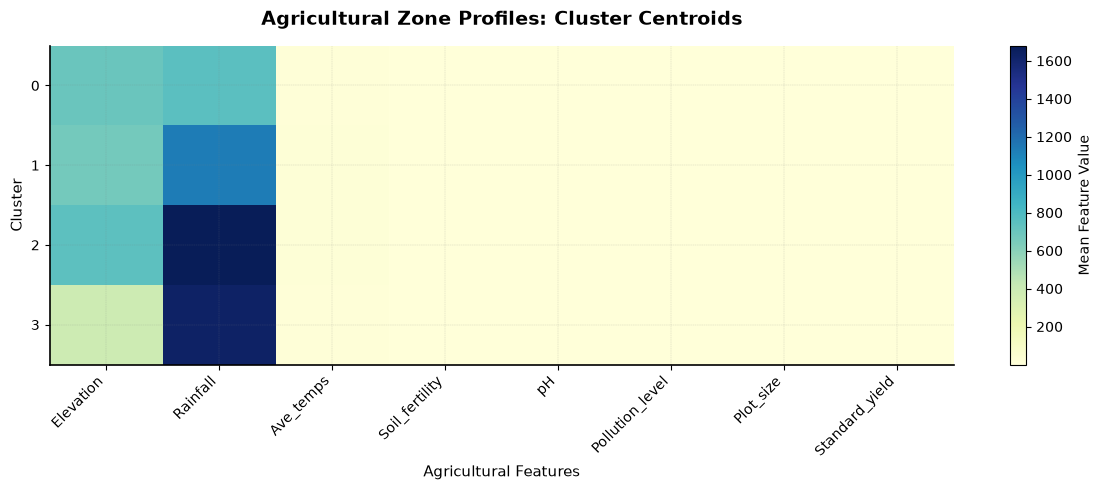

In [22]:
# Plot cluster centroid heatmap
fig, ax = plt.subplots(figsize=(12, 5))

im = ax.imshow(
    centroids,
    aspect='auto',
    cmap='YlGnBu'
)

# Configure axis ticks and labels
ax.set_xticks(range(len(centroids.columns)))
ax.set_xticklabels(
    centroids.columns,
    rotation=45,
    ha='right'
)

ax.set_yticks(range(len(centroids.index)))
ax.set_yticklabels(centroids.index)

# Apply consistent plot styling
style_plot(
    ax,
    title='Agricultural Zone Profiles: Cluster Centroids',
    xlabel='Agricultural Features',
    ylabel='Cluster',
    legend=False
)

# Add colorbar
plt.colorbar(im, ax=ax, label='Mean Feature Value')

plt.tight_layout()
plt.show()

#### **Observations**

The heatmap provides a visual comparison of the four agricultural clusters (0–3) across eight environmental and operational features. It highlights differences in the average characteristics of each zone and shows how the clusters are distributed across the measured variables.

**1. Cluster Overview**

The four clusters represent distinct agricultural profiles based on elevation, rainfall, average temperature, soil fertility, pH, pollution level, plot size, and standard yield.

**2. Rainfall as a Primary Discriminator**

Rainfall shows the greatest variation across the clusters:

- **Clusters 2 and 3** have the highest average rainfall, approximately 1,680 and 1,628, respectively.
- **Cluster 1** has moderate rainfall of approximately 1,131.
- **Cluster 0** records the lowest average rainfall at approximately 751.

This suggests that rainfall is an important feature distinguishing the four agricultural zones.

**3. Elevation Profiles**

Elevation also contributes to the differences between clusters.

- Clusters 0, 1, and 2 have relatively similar elevation levels, ranging from approximately 669 to 743.
- Cluster 3 has a substantially lower average elevation of approximately 385.

This indicates that Cluster 3 represents fields located at comparatively lower elevations.

**4. Remaining Features**

The other features, including average temperature, soil fertility, pH, pollution level, plot size, and standard yield, show smaller numerical magnitudes than rainfall and elevation in the raw-centroid heatmap.

However, this does not necessarily mean they contribute less to the clustering process. Their measurement scales differ, and the original K-Means analysis used standardised features.

#### **Conclusion**

The heatmap suggests that rainfall and elevation provide the most visually prominent differences among the four agricultural zones. Clusters 2 and 3 are distinguished by higher rainfall, while Cluster 3 also has substantially lower elevation. These differences provide useful environmental profiles for understanding the agricultural zones identified by K-Means.

**Technical note:** 

Because this heatmap displays raw centroid values, the colour intensity is influenced by the measurement scales of the features. Therefore, lighter colours for soil fertility, pH, or standard yield should not be interpreted as evidence that these variables are less important in forming the clusters. A heatmap of standardised centroids would provide a fairer comparison of relative feature patterns across clusters.